# 05 — Evaluation & Business Impact

A model that ranks risk isn't yet a *decision*. Turning a probability into a lending
policy requires the **economics**: how much do we lose on a default vs. earn on a good loan?

This notebook builds the bridge from **P(default)** → **approve/decline decision** → **dollars**.

1. Threshold selection by **expected profit**, not arbitrary 0.5
2. Precision/recall view for the rare positive class
3. Calibration — are the probabilities trustworthy?
4. A **portfolio simulation** with a dollar P&L story
5. A simple, explainable **scorecard** (points)

The goal is a defensible answer to: *"Should we approve this borrower, and why?"*

In [1]:
import pandas as pd
import numpy as np
import joblib
import json
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, confusion_matrix,
)

pd.set_option("display.max_columns", None)
import seaborn as sns
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
target = "SeriousDlqin2yrs"

test = pd.read_csv("../data/processed/test_clean.csv", index_col=0)
meta = json.load(open("../models/metadata.json"))
features = meta["features"]
X_test, y_test = test[features], test[target]

xgb = joblib.load("../models/xgboost.joblib")
logit = joblib.load("../models/logistic.joblib")
xgb_cal = joblib.load("../models/xgboost_calibrated.joblib")

# We use the CALIBRATED model for any decision that depends on the *level* of risk.
pd_xgb = xgb_cal.predict_proba(X_test)[:, 1]
pd_logit = logit.predict_proba(X_test)[:, 1]

print(f"test rows: {len(y_test):,} | default rate {y_test.mean():.2%}")
print(f"mean PD (calibrated): {pd_xgb.mean():.4f}")
print(f"XGBoost AUC {roc_auc_score(y_test, pd_xgb):.4f} | "
      f"Logistic AUC {roc_auc_score(y_test, pd_logit):.4f}")

test rows: 30,000 | default rate 6.68%
mean PD (calibrated): 0.0672
XGBoost AUC 0.8671 | Logistic AUC 0.8626


## 1. Choosing the threshold from economics

The "right" cutoff isn't 0.5 — it's the one that maximizes expected profit given the
**cost of mistakes**:

- **False negative** (approve a defaulter): lose the principal at default →
  **$10,000** exposure × **60%** loss-given-default = **$6,000**.
- **False positive** (decline a good borrower): forgo the earned interest/fees →
  **$1,500** profit.

**Key insight — the theoretical breakeven.** Approving is worth it while
`(1-PD)·profit > PD·loss`, i.e. while `PD < profit / (profit + loss)`. With these
numbers that's `1500 / 7500 = 0.20`. The *empirical* optimum can differ from the
theoretical one because the model's probabilities are compressed — so we scan the full
range rather than assuming.

In [2]:
# --- Business assumptions (illustrative) ---  use CALIBRATED PDs ---
LOAN_AMOUNT = 10_000       # average exposure
LGD = 0.60                 # loss given default
LOSS_ON_DEFAULT = LOAN_AMOUNT * LGD     # $6,000 lost if a defaulter is approved
PROFIT_ON_GOOD = 1_500     # profit if a good borrower is approved

theoretical_breakeven = PROFIT_ON_GOOD / (PROFIT_ON_GOOD + LOSS_ON_DEFAULT)

print(f"Loss per approved default : ${LOSS_ON_DEFAULT:,.0f}")
print(f"Profit per approved good  : ${PROFIT_ON_GOOD:,.0f}")
print(f"Theoretical breakeven PD  : {theoretical_breakeven:.3f}")


def profit_at_threshold(y_true, pd_scores, threshold):
    approve = pd_scores < threshold          # approve if PD below cutoff
    approved_good = ((approve == 1) & (y_true == 0)).sum()
    approved_bad = ((approve == 1) & (y_true == 1)).sum()
    profit = approved_good * PROFIT_ON_GOOD - approved_bad * LOSS_ON_DEFAULT
    return profit, approve.sum(), approved_good, approved_bad

Loss per approved default : $6,000
Profit per approved good  : $1,500
Theoretical breakeven PD  : 0.200


In [3]:
thresholds = np.arange(0.01, 0.99, 0.01)
rows = []
for t in thresholds:
    p, n_appr, g, b = profit_at_threshold(y_test.to_numpy(), pd_xgb, t)
    rows.append({"threshold": t, "profit": p, "approved": n_appr,
                 "approved_good": g, "approved_bad": b})
curve = pd.DataFrame(rows)

best = curve.loc[curve["profit"].idxmax()]
print("Optimal threshold by expected profit:")
print(best.to_string())

Optimal threshold by expected profit:
threshold               0.19
profit           33813000.00
approved            27137.00
approved_good       26218.00
approved_bad          919.00


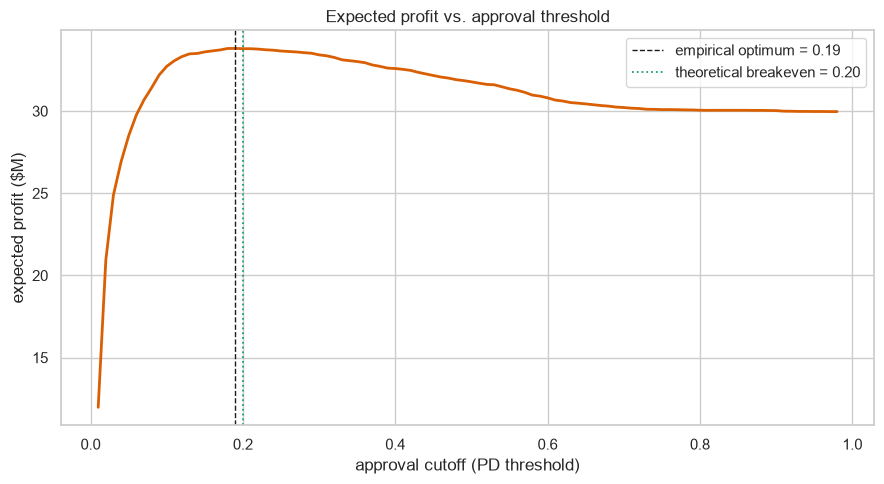

In [4]:
plt.figure(figsize=(9, 5))
plt.plot(curve["threshold"], curve["profit"] / 1e6, color="#d95f02", linewidth=2)
plt.axvline(best["threshold"], color="k", linestyle="--", linewidth=1,
            label=f"empirical optimum = {best['threshold']:.2f}")
plt.axvline(theoretical_breakeven, color="#1b9e77", linestyle=":", linewidth=1.3,
            label=f"theoretical breakeven = {theoretical_breakeven:.2f}")
plt.xlabel("approval cutoff (PD threshold)")
plt.ylabel("expected profit ($M)")
plt.title("Expected profit vs. approval threshold")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/impact_profit_curve.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretation:** profit rises as we approve more (each good borrower is worth $1,500),
then falls once the marginal applicant's default risk outweighs their profit. The curve
peaks at the empirical optimum and the theoretical breakeven marker shows the cost-model
intuition. This single chart is the "so what" of the whole project.

## 2. Precision / recall for the rare class

Because defaulters are rare, we watch the **precision–recall** curve and average precision
(AP), which are more honest than ROC when positives are scarce.

Average precision (PR-AUC) — XGBoost 0.3983 | Logistic 0.3927
Baseline (random) = positive rate = 0.0668


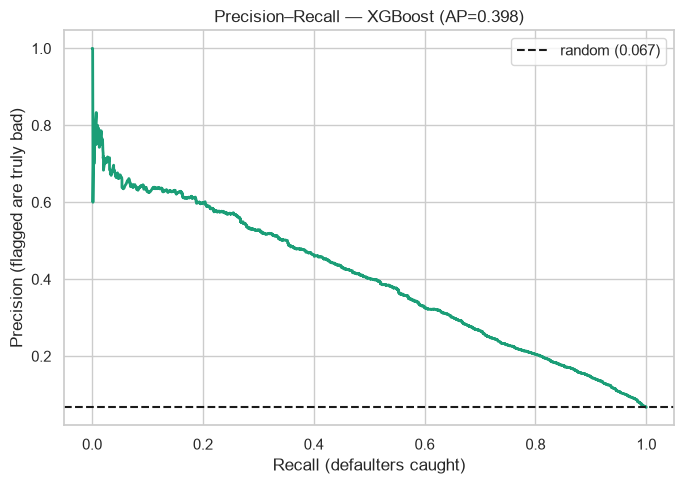

In [5]:
ap_xgb = average_precision_score(y_test, pd_xgb)
ap_logit = average_precision_score(y_test, pd_logit)
print(f"Average precision (PR-AUC) — XGBoost {ap_xgb:.4f} | Logistic {ap_logit:.4f}")
print(f"Baseline (random) = positive rate = {y_test.mean():.4f}")

prec, rec, thr = precision_recall_curve(y_test, pd_xgb)
plt.figure(figsize=(7, 5))
plt.plot(rec, prec, color="#1b9e77", linewidth=2)
plt.axhline(y_test.mean(), color="k", linestyle="--", label=f"random ({y_test.mean():.3f})")
plt.xlabel("Recall (defaulters caught)")
plt.ylabel("Precision (flagged are truly bad)")
plt.title(f"Precision–Recall — XGBoost (AP={ap_xgb:.3f})")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/impact_pr_curve.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. Calibration — can we trust the probabilities?

A good ranking (AUC) doesn't guarantee good probabilities. If we lend based on PD, the
predicted PD should match the observed default rate. We bin predictions and compare.

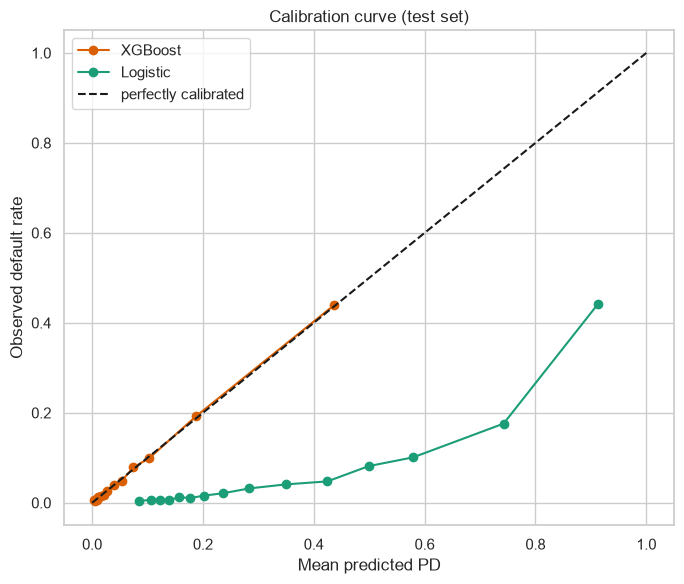

In [6]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(7, 6))
for name, score, color in [("XGBoost", pd_xgb, "#d95f02"), ("Logistic", pd_logit, "#1b9e77")]:
    frac_pos, mean_pred = calibration_curve(y_test, score, n_bins=15, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name, color=color)
ax.plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
ax.set_xlabel("Mean predicted PD")
ax.set_ylabel("Observed default rate")
ax.set_title("Calibration curve (test set)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/impact_calibration.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretation:** points near the diagonal mean the PDs are meaningful in absolute
terms. Deviations (often at the extremes) tell us whether to recalibrate — important when
the PD feeds pricing or capital calculations, not just ranking.

> The served model is already **isotonic-calibrated** (see notebook 04), so the PDs used
> here are on the correct absolute scale. Ranking metrics (AUC/KS) are unaffected by calibration.

## 4. Portfolio simulation — the dollar story

Apply the optimal cutoff to the test portfolio and compare against two policies:
**(a) approve everyone**, **(b) the model's policy**. This quantifies the value added.

In [7]:
y = y_test.to_numpy()
t_opt = float(best["threshold"])

# Policy A: approve everyone
profit_all = (y == 0).sum() * PROFIT_ON_GOOD - (y == 1).sum() * LOSS_ON_DEFAULT

# Policy B: model at optimal threshold
profit_model, n_appr, g, b = profit_at_threshold(y, pd_xgb, t_opt)

# Policy C: naive 0.5 threshold
profit_naive, *_ = profit_at_threshold(y, pd_xgb, 0.50)

sim = pd.DataFrame({
    "policy": ["Approve everyone", "Naive cutoff 0.50", f"Model @ {t_opt:.2f}"],
    "approved": [len(y), (pd_xgb < 0.50).sum(), n_appr],
    "expected_profit": [profit_all, profit_naive, profit_model],
})
sim["lift_vs_approve_all"] = sim["expected_profit"] - profit_all
sim

,policy,approved,expected_profit,lift_vs_approve_all
0,Approve everyone,30000,29962500.0,0.0
1,Naive cutoff 0.50,29411,31779000.0,1816500.0
2,Model @ 0.19,27137,33813000.0,3850500.0


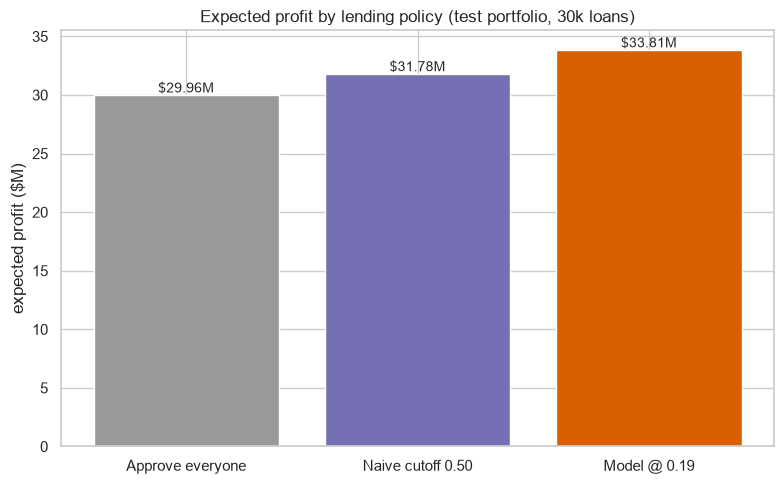

Model adds $3,850,500 vs approving everyone on this 30,000-loan test portfolio.


In [8]:
plt.figure(figsize=(8, 5))
colors = ["#999999", "#7570b3", "#d95f02"]
plt.bar(sim["policy"], sim["expected_profit"] / 1e6, color=colors)
for i, v in enumerate(sim["expected_profit"]):
    plt.text(i, v / 1e6, f"${v/1e6:.2f}M", ha="center", va="bottom", fontsize=10)
plt.ylabel("expected profit ($M)")
plt.title("Expected profit by lending policy (test portfolio, 30k loans)")
plt.tight_layout()
plt.savefig("../reports/figures/impact_policy_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Model adds ${(profit_model - profit_all):,.0f} vs approving everyone "
      f"on this 30,000-loan test portfolio.")

**This is the headline.** The model doesn't just rank better — it *makes money* by
declining the borrowers whose expected loss exceeds their expected profit.

*(Assumptions are illustrative; swap in a real risk appetite / pricing and the same
machinery produces the real cutoff.)*

## 5. An explainable scorecard

Regulated lending needs reasons. Convert the logistic model into **points** — a familiar
scorecard — so each borrower gets an interpretable score and per-feature contribution.

In [9]:
logit_coefs = pd.Series(logit.named_steps["clf"].coef_[0], index=features)
scaler = logit.named_steps["scaler"]

# Worked example: score a single borrower from the test set
i = 5
x = X_test.iloc[i:i+1]
z = scaler.transform(x)[0]
contrib = logit_coefs.values * z   # contribution of each feature to the log-odds

scorecard = pd.DataFrame({
    "feature": features,
    "value": x.values[0],
    "contribution_to_log_odds": contrib,
}).sort_values("contribution_to_log_odds", ascending=False)

pd_this = pd_logit[i]
print(f"Borrower # {X_test.index[i]} | predicted PD = {pd_this:.2%}")
print("Decision at optimal cutoff:",
      "DECLINE" if pd_this >= t_opt else "APPROVE")
scorecard

Borrower # 86740 | predicted PD = 8.39%
Decision at optimal cutoff: APPROVE


,feature,value,contribution_to_log_odds
11,income_missing,1.000000,0.046337
3,DebtRatio,29.000000,0.033596
4,MonthlyIncome,5400.000000,0.025406
16,is_high_util,0.000000,0.019006
14,income_per_dependent,5400.000000,0.010516
10,had_sentinel_delinq,0.000000,-0.004953
5,NumberOfOpenCreditLinesAndLoans,5.000000,-0.006753
2,NumberOfTime30-59DaysPastDueNotWorse,0.000000,-0.008513
9,NumberOfDependents,0.000000,-0.024822
8,NumberOfTime60-89DaysPastDueNotWorse,0.000000,-0.028927


### Takeaway

- **Thresholds are economic, not statistical.** The optimal cutoff came from the cost matrix.
- The model **beats both "approve everyone" and the naive 0.5 cutoff** in expected dollars.
- **Calibration** confirms the PDs are usable for pricing/capital, with a note to recalibrate if needed.
- The **scorecard** delivers per-borrower reasons — meeting the explainability bar lenders face.

**Bottom line:** this project goes from raw data → validated PD model → a defensible,
explainable, profit-maximizing lending policy. That's the full credit-risk analytics cycle.